In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M


In [14]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge 
#MEFF_SM = 0.05     # proximitized Ge
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs 


NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 for LSOC is within perturbative regime for widths atleast up to 100 nm 

LY = np.linspace(20, 100, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

#MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
#MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

MU_SM = 3*OMEGA/2 - 0.8
MU_SC = 3*OMEGA/2 - 0.8

K = 12

In [15]:
2*4*hbm/75**2/MEFF_SC

2.3579449364034835

In [19]:
2*4*hbm/66**2/MEFF_SC

3.044866911678052

In [6]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge 
#MEFF_SM = 0.05     # proximitized Ge
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs 


NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 for LSOC is within perturbative regime for widths atleast up to 100 nm 

LY = np.linspace(20, 100, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

#MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
#MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print(OMEGA)

MU_SM = -1 + 3*OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = -1 + 3*OMEGA/2        ## constant potential over reference level across all widths


print(MU_SM)

K = 8

Ep_li = np.empty((LY.shape[0],K) )
Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)


np.save("1d_linear_energy_vs_width_mu_{}.npy".format(MU_SM[0]), Ep_li)


[33.15860067 28.42815558 24.64224188 21.56516693 19.0304182  16.9176534
 15.13814859 13.62532901 12.32845058 11.20828849 10.23413601  9.38167742
  8.63145582  7.96775295  7.37775914  6.85095055  6.37861663  5.95349768
  5.56950428  5.22149796  4.90511844  4.61664634  4.35289339  4.11111395
  3.88893327  3.68428896  3.49538293  3.32064179  3.15868395  3.00829227
  2.86839106  2.73802688  2.61635215  2.50261145  2.39612966  2.29630199
  2.20258534  2.11449091  2.03157783  1.95344758  1.87973927  1.81012537
  1.74430817  1.68201651  1.62300301  1.56704162  1.51392545  1.46346483
  1.41548565  1.36982784  1.32634403]
[48.737901   41.64223337 35.96336281 31.34775039 27.5456273  24.3764801
 21.70722288 19.43799351 17.49267586 15.81243273 14.35120401 13.07251613
 11.94718373 10.95162942 10.06663871  9.27642583  8.56792494  7.93024652
  7.35425642  6.83224695  6.35767766  5.92496951  5.52934008  5.16667092
  4.83339991  4.52643344  4.2430744   3.98096269  3.73802593  3.5124384
  3.30258659  3.

In [7]:
print(OMEGA[-1]/2, OMEGA[-1]*3/2)

0.6631720133634798 1.9895160400904393


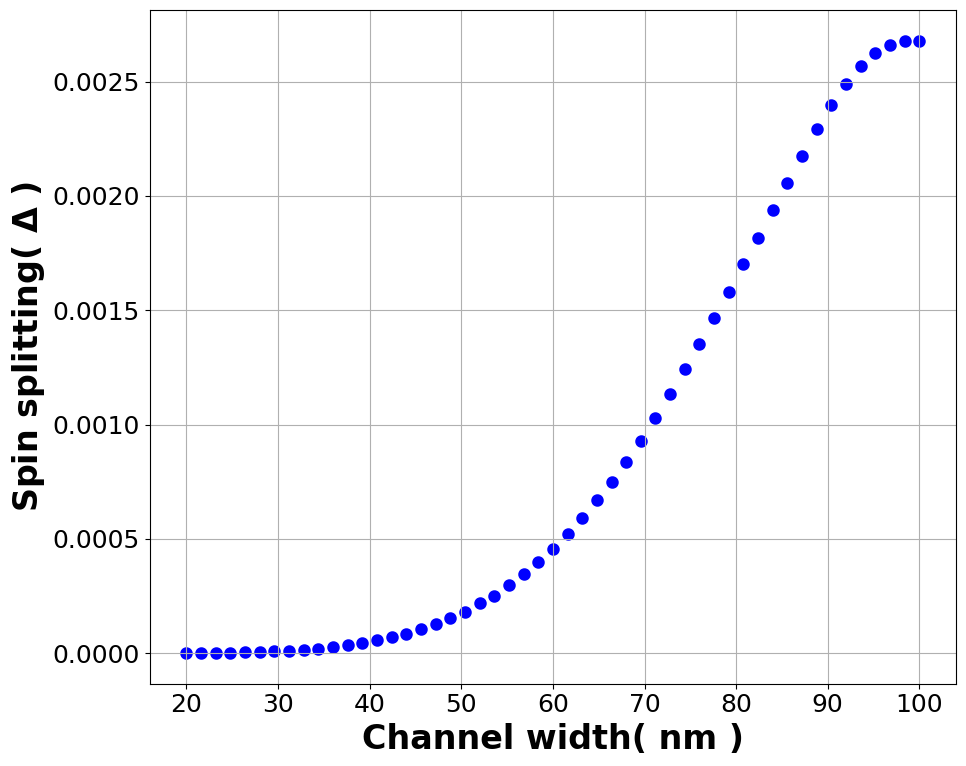

In [8]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Channel width( nm )', fontsize=24, weight='bold')
plt.ylabel(r'Spin splitting( $\mathbf{\Delta}$ )', fontsize=24, weight='bold')

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.grid(True)

plt.tight_layout()

plt.show()

In [6]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge
#MEFF_SM = 0.05     # Proximitized Ge
MEFF_SC = 0.023     # InAs
MEFF_SM = 0.023     # InAs

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(20, 100, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K = 12

Ep_cu = np.empty((LY.shape[0],K) )
#Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fcu = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)

np.save("1d_cubic_energy_vs_width.npy", Ep_cu)


0
10
20
30
40
50


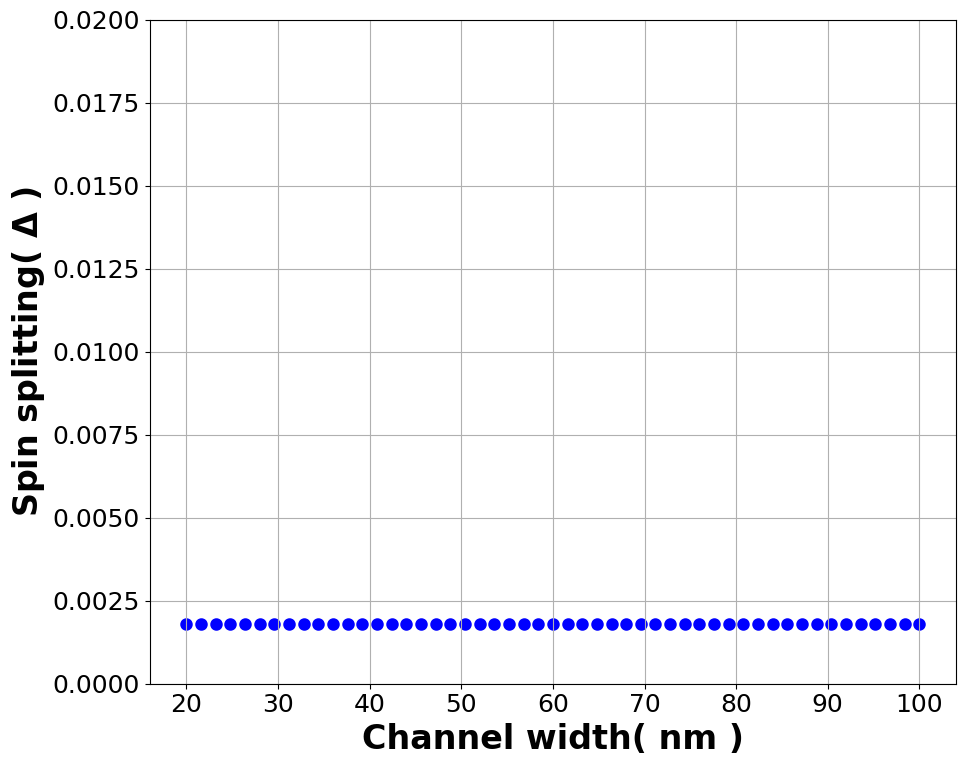

In [7]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Channel width( nm )', fontsize=24, weight='bold')
plt.ylabel(r'Spin splitting( $\mathbf{\Delta}$ )', fontsize=24, weight='bold')


# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.ylim(ymin=0, ymax= 0.020)

plt.grid(True)

plt.tight_layout()

plt.show()

NameError: name 'DELTA' is not defined

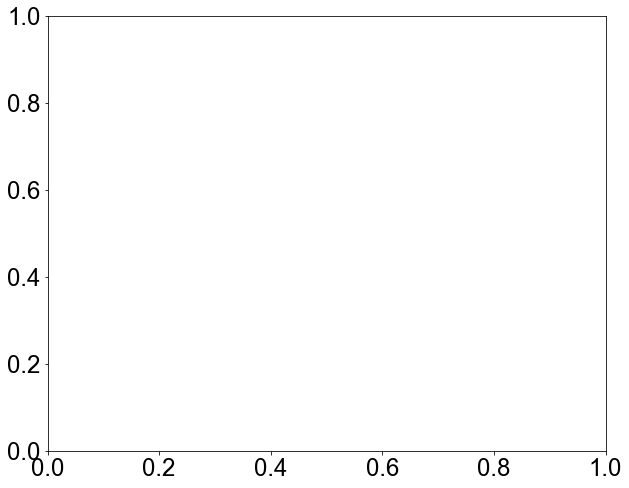

In [4]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]
Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')


plt.plot(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
plt.plot(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')

plt.xlabel(r'Channel width, $w$ (nm)', fontsize=32)
plt.ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=32)

# Adding labels near the lines
plt.text(20, 0.0005, r'linear spin-orbit coupling', fontsize=24, color='blue')  # Label for the first line
plt.text(20, 0.0019, r'cubic spin-orbit coupling', fontsize=24, color='red')    # Label for the second line



# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

#plt.ylim(ymin=0)

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], prop={'weight': 'bold'})

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], fontsize=30)

#plt.grid(True)

plt.tight_layout()

plt.show()

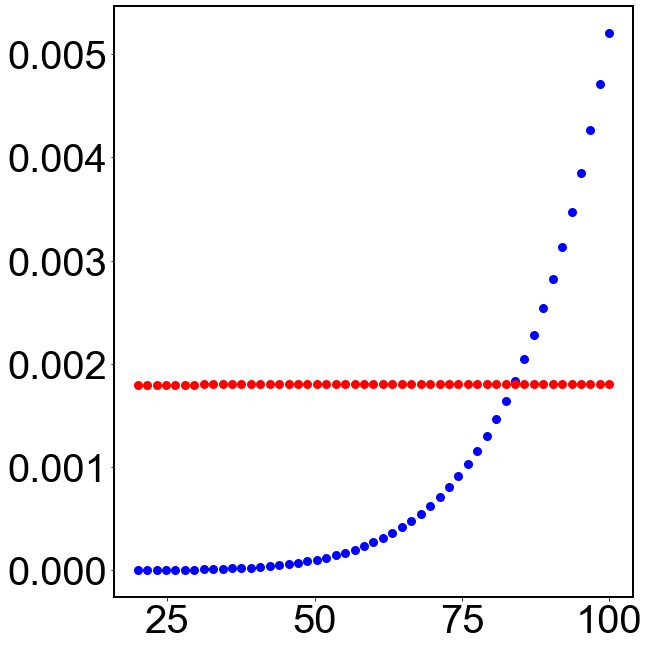

In [3]:
Ep_cu=np.load('1d_cubic_energy_vs_width.npy')
Ep_li=np.load('1d_linear_energy_vs_width.npy')

LY = np.linspace(20, 100, 51)

K=12

DELTA=0.165

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=40)

#f = plt.figure(figsize=(10, 10))

fig, ax = plt.subplots(figsize=(10, 10))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]
Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

#ax = plt.axis()

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')


ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box


#plt.plot(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
#plt.plot(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

#plt.xlabel(r'Channel width, $w$ (nm)', fontsize=32)
#plt.ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=32)

# Adding labels near the lines
#plt.text(20, 0.001, r'linear spin-orbit coupling', fontsize=28, color='blue')  # Label for the first line
#plt.text(20, 0.002, r'cubic spin-orbit coupling', fontsize=28, color='red')    # Label for the second line



# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

#plt.ylim(ymin=0)

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], prop={'weight': 'bold'})

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], fontsize=30)

#plt.grid(True)

plt.tight_layout()

plt.show()

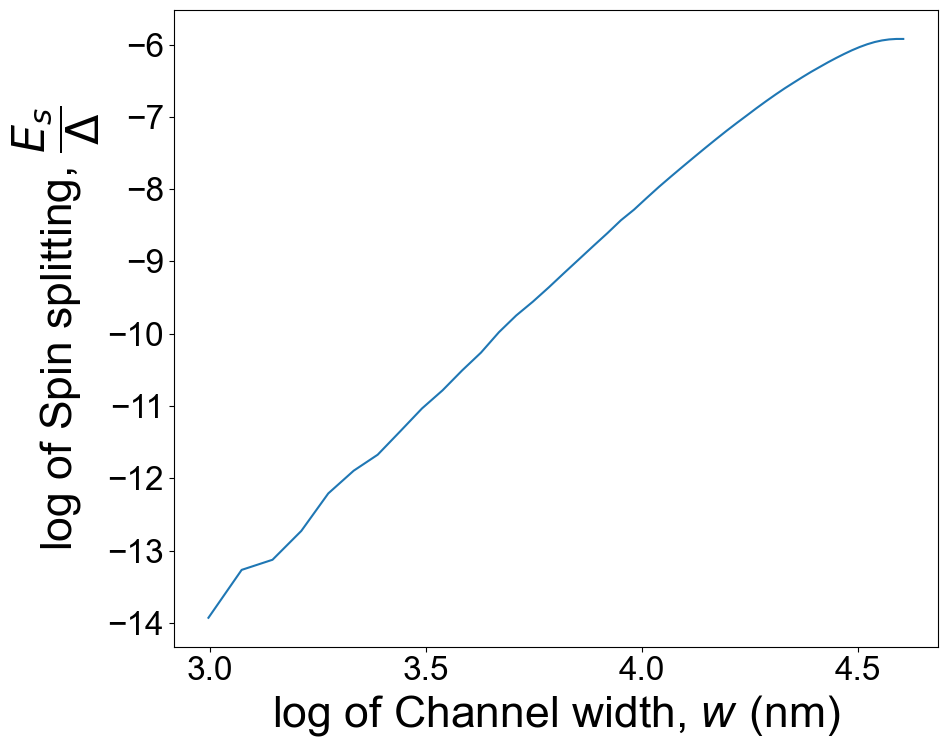

In [11]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]
Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

#plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
#plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')


#plt.plot(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
#plt.plot(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')
plt.plot(np.log(LY), np.log(Ep_Split_li/DELTA))


plt.xlabel(r'log of Channel width, $w$ (nm)', fontsize=32)
plt.ylabel(r'log of Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=32)

# Adding labels near the lines
#plt.text(20, 0.0005, r'linear spin-orbit coupling', fontsize=24, color='blue')  # Label for the first line
#plt.text(20, 0.0019, r'cubic spin-orbit coupling', fontsize=24, color='red')    # Label for the second line



# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

#plt.ylim(ymin=0)

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], prop={'weight': 'bold'})

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], fontsize=30)

#plt.grid(True)

plt.tight_layout()

plt.show()

In [12]:
slope = np.empty(Ep_li.shape[0]-1)
Es_li = np.log(Ep_Split_li/DELTA)
ly_li = np.log(LY)

for i in range(slope.shape[0]):

    slope[i] = Es_li[i+1] - Es_li[i]
    slope[i] = slope[i]/(ly_li[i+1]-ly_li[i])

In [13]:
print(slope)

[8.60964839e+00 1.96008391e+00 5.98252155e+00 8.30110336e+00
 5.34013747e+00 3.98004789e+00 6.20132327e+00 6.26982056e+00
 5.26286072e+00 6.06979307e+00 5.65016179e+00 6.78658960e+00
 5.77975894e+00 4.95255807e+00 5.36800528e+00 5.60140129e+00
 5.51059303e+00 5.52678519e+00 5.44460028e+00 5.69551957e+00
 4.84783887e+00 5.51001423e+00 5.40125837e+00 5.13150780e+00
 5.03389431e+00 4.98326709e+00 4.92526661e+00 4.84430636e+00
 4.74982792e+00 4.58858005e+00 4.46730837e+00 4.50534248e+00
 4.33830077e+00 4.19719031e+00 4.04131512e+00 3.80820866e+00
 3.75236703e+00 3.61852173e+00 3.38321223e+00 3.37253054e+00
 3.17031050e+00 3.00738036e+00 2.81713266e+00 2.51942805e+00
 2.18382672e+00 1.77753708e+00 1.30830522e+00 8.45225430e-01
 3.85431975e-01 4.98652458e-03]


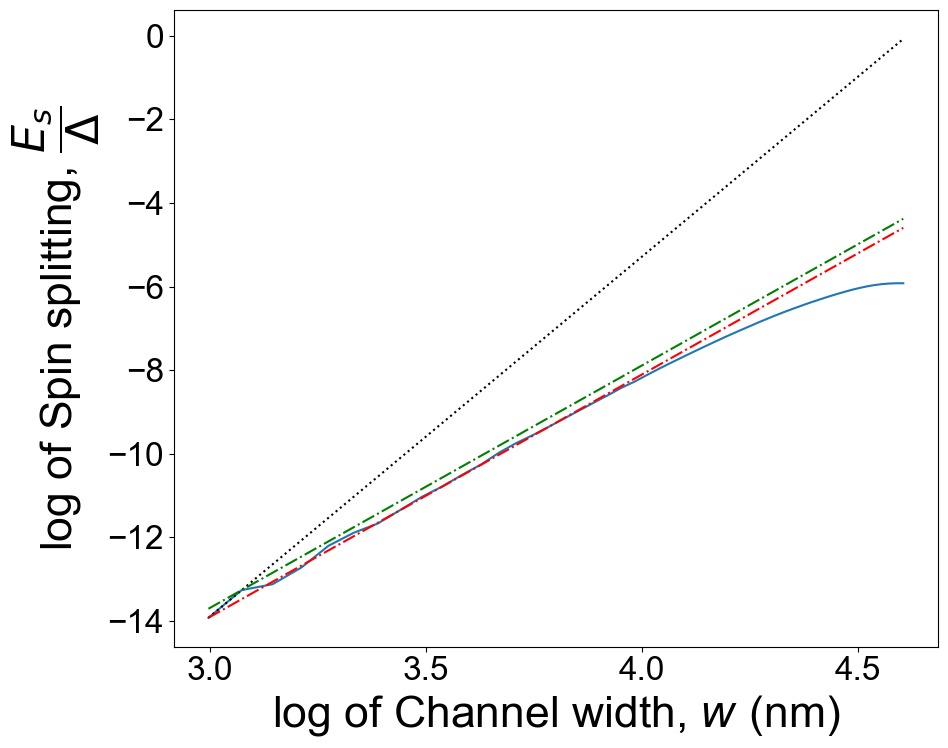

In [17]:
#### code for line with given slope passing through first two points for reference

X = ly_li 

Y1 = Es_li[0]
Y2 = Es_li[1]
X1 = X[0]
X2 = X[1] 

Y = (X - X2)*(Y2-Y1)/(X2-X1) + Y2

YNEW = 5.8*(X-X1) + Y1

YNEW2 = 5.8*(X-X2) + Y2

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

ax = plt.axis()

#plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
#plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')


#plt.plot(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
#plt.plot(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='red')
plt.plot(np.log(LY), np.log(Ep_Split_li/DELTA))
plt.plot(X, Y, linestyle =':' , color='black' )
plt.plot(X, YNEW, linestyle ='-.' , color='red' )
plt.plot(X, YNEW2, linestyle ='-.' , color='green' )

plt.xlabel(r'log of Channel width, $w$ (nm)', fontsize=32)
plt.ylabel(r'log of Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=32)

# Adding labels near the lines
#plt.text(20, 0.0005, r'linear spin-orbit coupling', fontsize=24, color='blue')  # Label for the first line
#plt.text(20, 0.0019, r'cubic spin-orbit coupling', fontsize=24, color='red')    # Label for the second line



# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

#plt.ylim(ymin=0)

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], prop={'weight': 'bold'})

#plt.legend(['Linear spin orbit coupling', 'Cubic spin orbit coupling'], fontsize=30)

#plt.grid(True)

plt.tight_layout()

plt.show()



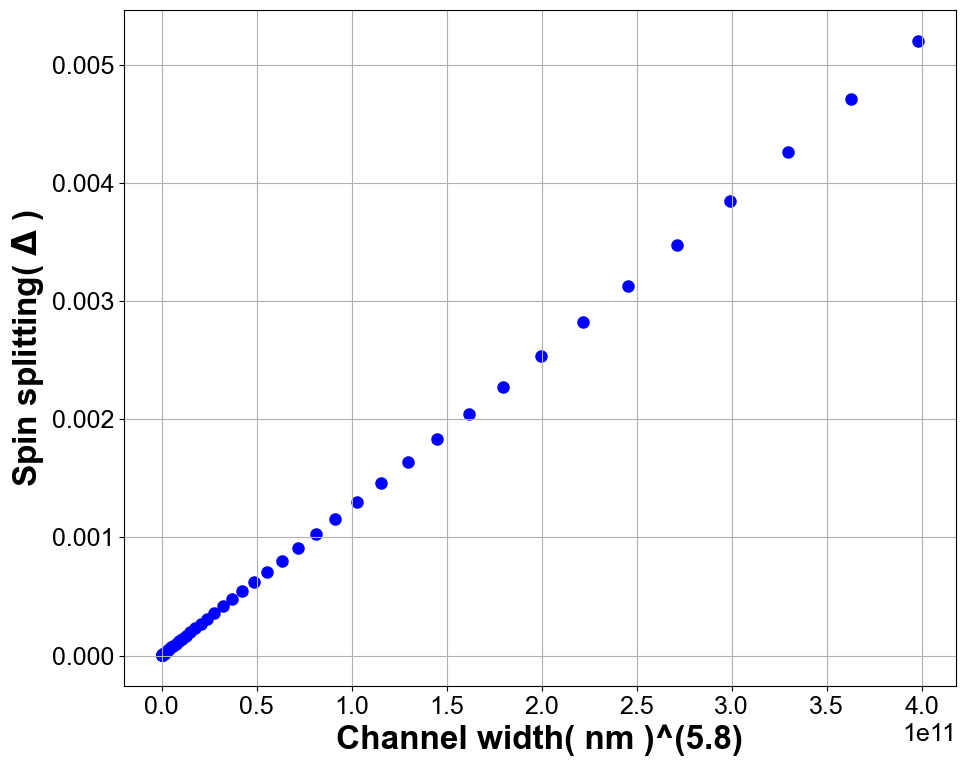

In [22]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

plt.scatter(LY**5.8, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Channel width( nm )^(5.8)', fontsize=24, weight='bold')
plt.ylabel(r'Spin splitting( $\mathbf{\Delta}$ )', fontsize=24, weight='bold')

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.grid(True)

plt.tight_layout()

plt.show()

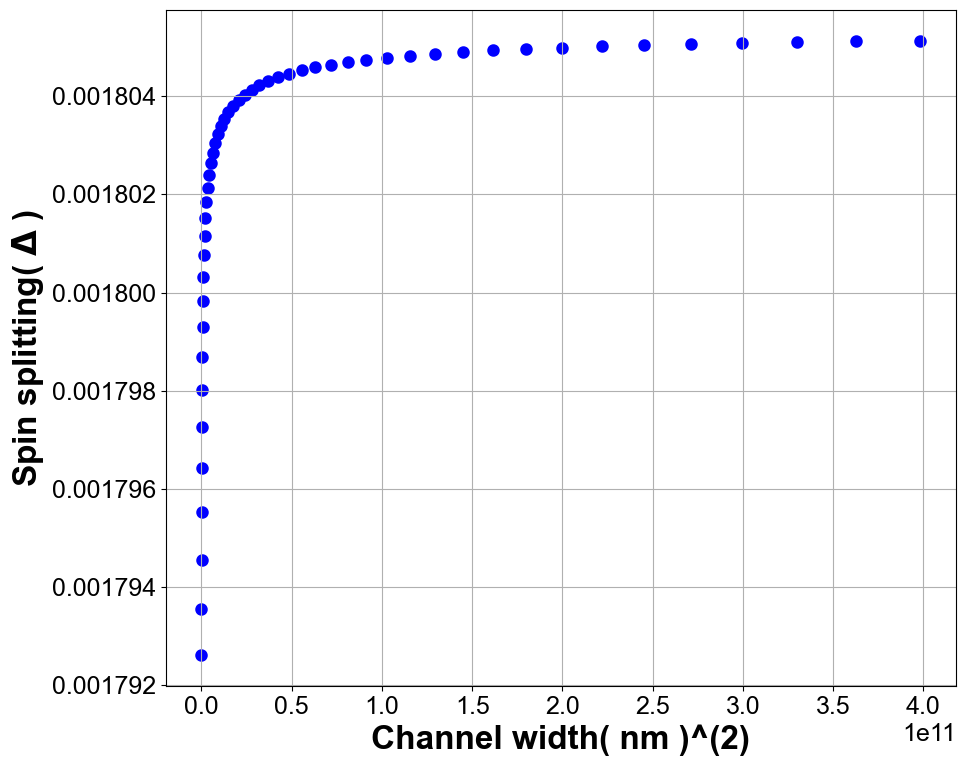

In [24]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

plt.scatter(LY**5.8, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Channel width( nm )^(2)', fontsize=24, weight='bold')
plt.ylabel(r'Spin splitting( $\mathbf{\Delta}$ )', fontsize=24, weight='bold')

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.grid(True)

plt.tight_layout()

plt.show()

In [33]:
(Y2-Y1)/(X2-X1) 

5.893037637308142

In [31]:
math.exp(3.5)

33.11545195869231

In [4]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 7             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge 
#MEFF_SM = 0.05     # proximitized Ge
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs 


NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 for LSOC is within perturbative regime for widths atleast up to 100 nm 

LY = np.linspace(20, 125, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K = 12

Ep_li = np.empty((LY.shape[0],K) )
Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)

0
10
20
30
40
50


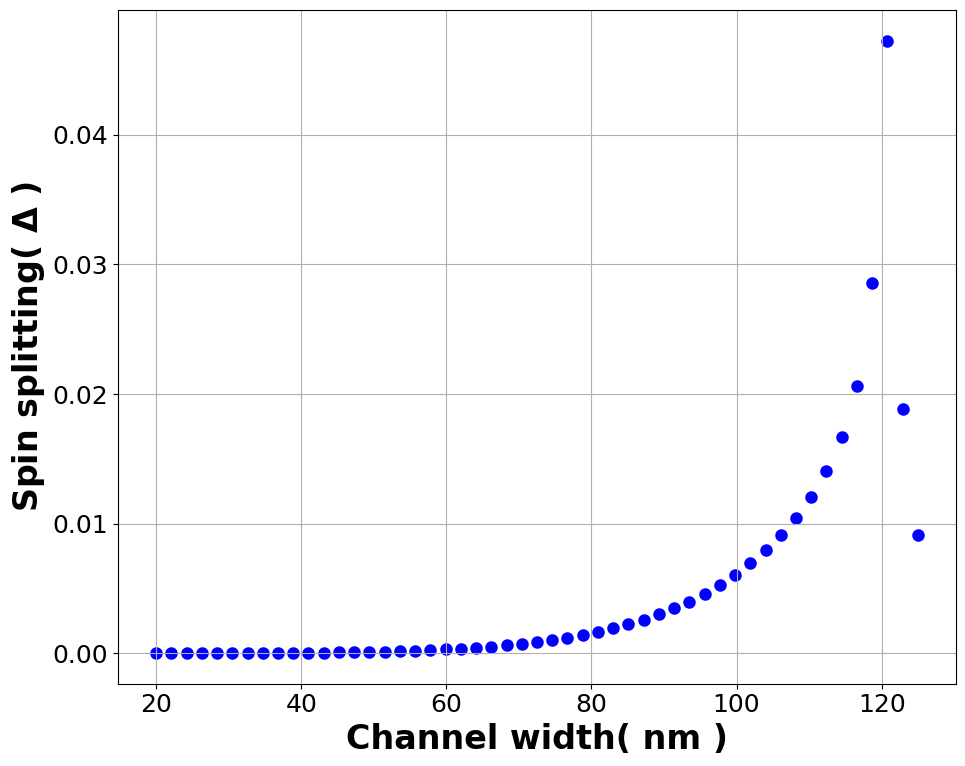

In [5]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Channel width( nm )', fontsize=24, weight='bold')
plt.ylabel(r'Spin splitting( $\mathbf{\Delta}$ )', fontsize=24, weight='bold')

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.grid(True)

plt.tight_layout()

plt.show()

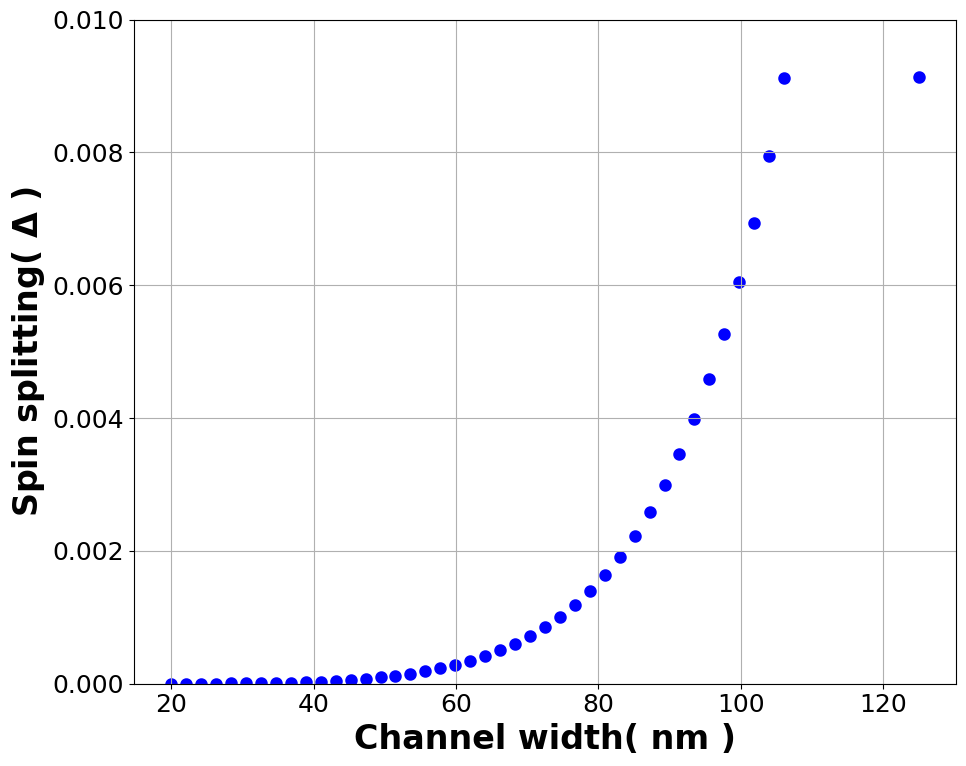

In [8]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Channel width( nm )', fontsize=24, weight='bold')
plt.ylabel(r'Spin splitting( $\mathbf{\Delta}$ )', fontsize=24, weight='bold')

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.ylim(ymin=0. , ymax = 0.01)

plt.grid(True)

plt.tight_layout()

plt.show()